<a href="https://colab.research.google.com/github/willian82/repositoria-google-colad/blob/main/actividad_2_6_implementaci_n_de_reglas_de_asociaci_n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd
import kagglehub

path = kagglehub.dataset_download("rashikrahmanpritom/groceries-dataset-for-market-basket-analysismba")
print(os.listdir(path))

100%|██████████| 455k/455k [00:00<00:00, 81.0MB/s]

Extracting files...
['basket.csv', 'Groceries data.csv']


# Paso 1: Preparar Colab y cargar el dataset

Crea una celda de código nueva debajo y pega esto:

In [ ]:
df = pd.read_csv(os.path.join(path, "Groceries data.csv"))
print(df.shape)
print(df.columns.tolist())
df.head()

(38765, 7)
['Member_number', 'Date', 'itemDescription', 'year', 'month', 'day', 'day_of_week']


,Member_number,Date,itemDescription,year,month,day,day_of_week
0,1808,2015-07-21,tropical fruit,2015,7,21,1
1,2552,2015-05-01,whole milk,2015,5,1,4
2,2300,2015-09-19,pip fruit,2015,9,19,5
3,1187,2015-12-12,other vegetables,2015,12,12,5
4,3037,2015-01-02,whole milk,2015,1,2,4


Después, en otra celda, saca los números que necesitas para describir el dataset:

In [ ]:
print("Filas:", len(df))
print("Transacciones:", df.groupby(["Member_number", "Date"]).ngroups)
print("Ítems distintos:", df["itemDescription"].nunique())

Filas: 38765
Transacciones: 14963
Ítems distintos: 167


Celda de Markdown (la escribes tú con tus palabras). Debe decir:

- Qué es una transacción en este dataset. Pista: no hay una columna “número de boleta”, así que hay que pensar qué combinación de columnas identifica una compra.

- Qué es un ítem.

- Cuántas filas, transacciones e ítems distintos hay, con los números que acabas de sacar.

# Paso 2: Revisar la calidad de los datos

Crea una celda de código nueva, pega esto y ejecútala:

In [ ]:
print("Nulos por columna:")
print(df.isna().sum())

print("\nFilas completamente duplicadas:", df.duplicated().sum())

items = df["itemDescription"]
print("Nombres con mayúsculas o espacios sobrantes:", (items != items.str.strip().str.lower()).sum())

print("\nTipos de datos:")
print(df.dtypes)

Nulos por columna:
Member_number      0
Date               0
itemDescription    0
year               0
month              0
day                0
day_of_week        0
dtype: int64

Filas completamente duplicadas: 759
Nombres con mayúsculas o espacios sobrantes: 823

Tipos de datos:
Member_number       int64
Date               object
itemDescription    object
year                int64
month               int64
day                 int64
day_of_week         int64
dtype: object


Esa celda revisa cuatro cosas: nulos, filas duplicadas, nombres de ítems inconsistentes y tipos de datos. Todavía no modifica nada, solo diagnostica.

# Paso 3: Ver y corregir los nombres

Crea una celda de código nueva y ejecútala:

In [ ]:
# 1. Ver ejemplos de nombres problemáticos
malos = items[items != items.str.strip().str.lower()].unique()
print("Ejemplos:", list(malos[:10]))
print("Ítems distintos ANTES:", items.nunique())

# 2. Normalizar: quitar espacios y pasar a minúsculas
df["itemDescription"] = df["itemDescription"].str.strip().str.lower()

# 3. Convertir la fecha a tipo fecha
df["Date"] = pd.to_datetime(df["Date"])

print("Ítems distintos DESPUÉS:", df["itemDescription"].nunique())
print(df.dtypes["Date"])

Ejemplos: ['cream cheese ', 'UHT-milk', 'Instant food products', 'roll products ']
Ítems distintos ANTES: 167
Ítems distintos DESPUÉS: 167
datetime64[ns]


La celda muestra algunos nombres con problemas, hace la corrección y compara cuántos ítems distintos había antes y después. Si el número baja, es porque había ítems que en realidad eran el mismo escrito de dos formas.

Las filas duplicadas son decisión tuya. Dejarlas no afecta, porque en el formato one-hot cada ítem solo vale verdadero o falso por transacción, así que una repetición dentro de la misma compra da igual. Lo que debes hacer es decidirlo y justificarlo en Markdown.

Celda de Markdown (con tus palabras): anota qué encontraste (sin nulos, 759 duplicadas, 823 nombres inconsistentes, fecha como texto), qué hiciste con cada cosa y cuántos ítems distintos quedaron.

# Paso 4: Una fila por transacción y one-hot

Crea una celda de código nueva y ejecútala:

In [ ]:
from mlxtend.preprocessing import TransactionEncoder

# Una lista de ítems por transacción (cliente + fecha); set() quita repetidos dentro de la misma compra
baskets = (df.groupby(["Member_number", "Date"])["itemDescription"]
             .apply(lambda x: sorted(set(x)))
             .tolist())

print("Transacciones:", len(baskets))
print("Primeras 3:", baskets[:3])

# Codificación one-hot (verdadero/falso)
te = TransactionEncoder()
basket = pd.DataFrame(te.fit(baskets).transform(baskets), columns=te.columns_)

print("Forma de la tabla:", basket.shape)
basket.head()

Transacciones: 14963
Primeras 3: [['pastry', 'salty snack', 'whole milk'], ['sausage', 'semi-finished bread', 'whole milk', 'yogurt'], ['pickled vegetables', 'soda']]
Forma de la tabla: (14963, 167)


,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,beverages,bottled beer,...,uht-milk,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


La celda hace dos cosas. Primero arma la lista de ítems de cada compra. Luego la convierte en una tabla con una fila por transacción y una columna por ítem, con verdadero o falso según si el ítem estaba en esa compra.

# Paso 5: Mirar la distribución de frecuencias

Aquí empieza una decisión tuya: el soporte mínimo. Primero hay que ver qué tan frecuentes son los ítems. Crea una celda nueva y ejecútala:

In [ ]:
freq = basket.mean().sort_values(ascending=False)   # soporte de cada ítem

print("Los 15 ítems más frecuentes:")
print(freq.head(15).round(4))

print("\nResumen de los soportes de los 167 ítems:")
print(freq.describe().round(4))

print("\nÍtems con soporte >= 5%:", (freq >= 0.05).sum())
print("Ítems con soporte >= 2%:", (freq >= 0.02).sum())
print("Ítems con soporte >= 1%:", (freq >= 0.01).sum())

Los 15 ítems más frecuentes:
whole milk          0.1579
other vegetables    0.1221
rolls/buns          0.1100
soda                0.0971
yogurt              0.0859
root vegetables     0.0696
tropical fruit      0.0678
bottled water       0.0607
sausage             0.0603
citrus fruit        0.0531
pastry              0.0517
pip fruit           0.0491
shopping bags       0.0476
canned beer         0.0469
bottled beer        0.0453
dtype: float64

Resumen de los soportes de los 167 ítems:
count    167.0000
mean       0.0152
std        0.0234
min        0.0001
25%        0.0020
50%        0.0057
75%        0.0176
max        0.1579
dtype: float64

Ítems con soporte >= 5%: 11
Ítems con soporte >= 2%: 38
Ítems con soporte >= 1%: 64


Cada columna de basket vale True o False, así que su promedio es la proporción de compras que contienen ese ítem, o sea su soporte.

# Paso 6: Probar un soporte y ver cuántos itemsets salen

La decisión de qué soporte usar es tuya. Para decidir con datos, prueba uno y mira cuántos itemsets aparecen. Partamos del 2 % solo como punto de comparación:

In [ ]:
from mlxtend.frequent_patterns import apriori

MIN_SUPPORT = 0.02   # cámbialo para probar otros valores

itemsets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
itemsets["n_items"] = itemsets["itemsets"].apply(len)

print("Soporte mínimo:", MIN_SUPPORT)
print("Itemsets frecuentes:", len(itemsets))
print(itemsets["n_items"].value_counts().sort_index())
itemsets.sort_values("support", ascending=False).head(10)

Soporte mínimo: 0.02
Itemsets frecuentes: 38
n_items
1    38
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets,n_items
36,0.157923,(whole milk),1
23,0.122101,(other vegetables),1
27,0.110005,(rolls/buns),1
31,0.097106,(soda),1
37,0.085879,(yogurt),1
28,0.069572,(root vegetables),1
32,0.067767,(tropical fruit),1
3,0.060683,(bottled water),1
29,0.060349,(sausage),1
9,0.053131,(citrus fruit),1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Esa celda cuenta cuántos itemsets hay en total y cuántos tienen 1, 2 o más ítems. Lo que importa es cuántos de 2 o más ítems salen, porque solo con esos se pueden formar reglas.

# Paso 7: Probar varios soportes y comparar

Para decidir con datos, prueba varios valores bajando de a poco. Crea una celda nueva y ejecútala:

In [ ]:
import warnings
warnings.filterwarnings("ignore")

for s in [0.02, 0.015, 0.01, 0.0075, 0.005]:
    it = apriori(basket, min_support=s, use_colnames=True)
    n_items = it["itemsets"].apply(len)
    print(f"soporte {s}: total={len(it)} | de 1 ítem={int((n_items==1).sum())} | de 2 ítems={int((n_items==2).sum())} | de 3+ ítems={int((n_items>=3).sum())}")

soporte 0.02: total=38 | de 1 ítem=38 | de 2 ítems=0 | de 3+ ítems=0
soporte 0.015: total=50 | de 1 ítem=50 | de 2 ítems=0 | de 3+ ítems=0
soporte 0.01: total=69 | de 1 ítem=64 | de 2 ítems=5 | de 3+ ítems=0
soporte 0.0075: total=86 | de 1 ítem=74 | de 2 ítems=12 | de 3+ ítems=0
soporte 0.005: total=126 | de 1 ítem=89 | de 2 ítems=37 | de 3+ ítems=0


Para cada soporte, la celda cuenta cuántos itemsets hay en total y cuántos tienen 1, 2 o 3 o más ítems. Lo que te interesa son los de 2 o más ítems, porque de ahí salen las reglas.

Me detuve en 0,005 a propósito: un soporte muy bajo puede generar demasiados itemsets y agotar la memoria de Colab, y la guía lo advierte. No bajes de ahí sin ver antes el resultado.

# Paso 8: Generar las reglas

Elige un soporte (por ejemplo 0,005 para empezar) y crea una celda nueva:

In [ ]:
from mlxtend.frequent_patterns import association_rules

MIN_SUPPORT = 0.005      # tu decisión
MIN_CONFIDENCE = 0.05    # parte bajo y súbelo después

itemsets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
rules = association_rules(itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)
# si da error por "num_itemsets", usa: association_rules(itemsets, num_itemsets=len(basket), metric="confidence", min_threshold=MIN_CONFIDENCE)

print("Reglas generadas:", len(rules))
cols = ["antecedents", "consequents", "support", "confidence", "lift"]
rules[cols].sort_values("lift", ascending=False).head(10)

Reglas generadas: 57


,antecedents,consequents,support,confidence,lift
6,(frankfurter),(other vegetables),0.005146,0.136283,1.116150
42,(yogurt),(sausage),0.005748,0.066926,1.108986
43,(sausage),(yogurt),0.005748,0.095238,1.108986
39,(sausage),(soda),0.005948,0.098560,1.014975
38,(soda),(sausage),0.005948,0.061253,1.014975
0,(bottled beer),(whole milk),0.007151,0.157817,0.999330
40,(sausage),(whole milk),0.008955,0.148394,0.939663
41,(whole milk),(sausage),0.008955,0.056708,0.939663
8,(newspapers),(whole milk),0.005614,0.144330,0.913926
5,(domestic eggs),(whole milk),0.005280,0.142342,0.901341


La celda genera las reglas y muestra las 10 con mayor lift. Cada par puede dar hasta dos reglas, una por dirección, y la confianza mínima decide cuáles sobreviven.

# Paso 9: Experimento con tres configuraciones

La actividad pide una tabla con al menos tres combinaciones de soporte y confianza. Crea una celda nueva y ejecútala:

In [ ]:
import warnings
warnings.filterwarnings("ignore")

configs = [(0.01, 0.05), (0.0075, 0.05), (0.005, 0.05), (0.005, 0.10)]   # cámbialas a gusto

filas = []
for s, c in configs:
    it = apriori(basket, min_support=s, use_colnames=True)
    rl = association_rules(it, metric="confidence", min_threshold=c) if len(it) > 1 else []
    filas.append({
        "soporte_min": s,
        "confianza_min": c,
        "n_itemsets": len(it),
        "n_reglas": len(rl),
        "lift_max": round(rl["lift"].max(), 3) if len(rl) else None,
    })

pd.DataFrame(filas)

,soporte_min,confianza_min,n_itemsets,n_reglas,lift_max
0,0.0100,0.05,69,10,0.823
1,0.0075,0.05,86,23,0.940
2,0.0050,0.05,126,57,1.116
3,0.0050,0.10,126,19,1.116


La celda repite el proceso con cada combinación y arma la tabla con el número de itemsets y reglas, que es la evidencia que pide la guía. Agregué lift_max porque ayuda a ver si relajar los umbrales trae reglas más fuertes o solo más ruido.

# Paso 10: Ver todas las reglas de tu configuración

Elige la configuración con la que vas a trabajar y crea una celda nueva. Con 0,005 y 0,05 son 57 reglas y con 0,005 y 0,10 son 19; puedes ver cualquiera:

In [ ]:
MIN_SUPPORT = 0.005      # tu configuración elegida
MIN_CONFIDENCE = 0.10

itemsets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
rules = association_rules(itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)

# Pasar los conjuntos a texto para leerlos mejor
rules["regla"] = rules["antecedents"].apply(lambda x: ", ".join(sorted(x))) + " => " + rules["consequents"].apply(lambda x: ", ".join(sorted(x)))
rules["n_compras"] = (rules["support"] * len(basket)).round().astype(int)

tabla = rules[["regla", "n_compras", "support", "confidence", "lift"]].sort_values("lift", ascending=False)
pd.set_option("display.max_rows", 100)
tabla.round(3)

,regla,n_compras,support,confidence,lift
5,frankfurter => other vegetables,77,0.005,0.136,1.116
0,bottled beer => whole milk,107,0.007,0.158,0.999
14,sausage => whole milk,134,0.009,0.148,0.940
7,newspapers => whole milk,84,0.006,0.144,0.914
4,domestic eggs => whole milk,79,0.005,0.142,0.901
6,frankfurter => whole milk,79,0.005,0.140,0.885
11,pork => whole milk,75,0.005,0.135,0.856
10,pip fruit => whole milk,99,0.007,0.135,0.854
3,citrus fruit => whole milk,107,0.007,0.135,0.852
15,shopping bags => whole milk,95,0.006,0.133,0.845


La celda muestra todas las reglas ordenadas por lift, con una columna extra (n_compras) que te dice en cuántas compras se apoya cada una. Mirar esa columna junto al lift es lo que te va a permitir juzgar qué reglas valen la pena.

Con esa tabla vas a:

- Elegir 5 reglas que te parezcan valiosas y explicar cada una en una oración de negocio, sin jerga.
- Buscar una regla que descartarías aunque cumpla tus umbrales, justificada con sus métricas.

# Paso 11: Ver solo las reglas con asociación real

Crea una celda nueva y ejecútala:

In [ ]:
MIN_SUPPORT = 0.005
MIN_CONFIDENCE = 0.05     # cámbialo si eliges el otro camino

itemsets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
rules = association_rules(itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)

rules["regla"] = rules["antecedents"].apply(lambda x: ", ".join(sorted(x))) + " => " + rules["consequents"].apply(lambda x: ", ".join(sorted(x)))
rules["n_compras"] = (rules["support"] * len(basket)).round().astype(int)

print("Reglas totales:", len(rules))
print("Con lift > 1:", (rules["lift"] > 1).sum())
print("Con lift < 1:", (rules["lift"] < 1).sum())

rules[rules["lift"] > 1][["regla", "n_compras", "support", "confidence", "lift"]].sort_values("lift", ascending=False).round(3)

Reglas totales: 57
Con lift > 1: 5
Con lift < 1: 52


,regla,n_compras,support,confidence,lift
6,frankfurter => other vegetables,77,0.005,0.136,1.116
43,sausage => yogurt,86,0.006,0.095,1.109
42,yogurt => sausage,86,0.006,0.067,1.109
39,sausage => soda,89,0.006,0.099,1.015
38,soda => sausage,89,0.006,0.061,1.015


La celda cuenta cuántas reglas tienen lift mayor y menor que 1, y muestra las que superan 1 junto con la cantidad de compras que las respaldan.

Cuando salgan, vas a elegir tus 5 reglas y escribir una oración de negocio para cada una, sin jerga. Antes de decidir, mira estas tres cosas de cada regla:

- Su lift: ¿qué tan por encima de 1 está?
- Su n_compras: ¿en cuántas compras se apoya?
- Si hay parejas en ambas direcciones (A => B y B => A): son la misma asociación contada dos veces, y puedes decidir si cuentan como una o dos reglas.

# Paso 12: Verificar una regla contando a mano

La guía recomienda comprobar una regla contando sobre una muestra pequeña, como en la 2.5. Crea una celda nueva:

In [ ]:
import random

A, B = "frankfurter", "other vegetables"   # cambia por la regla que quieras verificar

# 1) Verificación con todos los datos
n = len(basket)
n_A = int(basket[A].sum())
n_B = int(basket[B].sum())
n_AB = int((basket[A] & basket[B]).sum())
soporte = n_AB / n
confianza = n_AB / n_A
lift = confianza / (n_B / n)
print(f"Con A: {n_A} | con B: {n_B} | con ambos: {n_AB} | total: {n}")
print(f"soporte={soporte:.4f}  confianza={confianza:.4f}  lift={lift:.4f}")

# 2) Muestra pequeña para contar tú a mano (10 compras con A y 10 sin A)
random.seed(1)
con_A = [b for b in baskets if A in b]
sin_A = [b for b in baskets if A not in b]
muestra = random.sample(con_A, 10) + random.sample(sin_A, 10)
for i, b in enumerate(muestra):
    print(i, b)

print("\nSegún el código en esta muestra -> con A:", sum(A in b for b in muestra),
      "| con A y B:", sum((A in b) and (B in b) for b in muestra))

Con A: 565 | con B: 1827 | con ambos: 77 | total: 14963
soporte=0.0051  confianza=0.1363  lift=1.1161
0 ['berries', 'bottled water', 'frankfurter', 'pickled vegetables', 'processed cheese']
1 ['bottled water', 'frankfurter']
2 ['frankfurter', 'frozen meals']
3 ['frankfurter', 'frozen vegetables', 'shopping bags']
4 ['canned fish', 'cream cheese', 'frankfurter', 'misc. beverages', 'nuts/prunes', 'root vegetables', 'uht-milk', 'whole milk']
5 ['chocolate', 'frankfurter']
6 ['candy', 'citrus fruit', 'coffee', 'frankfurter', 'fruit/vegetable juice', 'uht-milk']
7 ['cake bar', 'citrus fruit', 'frankfurter', 'ice cream', 'other vegetables', 'pip fruit', 'rolls/buns', 'spread cheese', 'yogurt']
8 ['beef', 'beverages', 'frankfurter', 'other vegetables', 'rolls/buns', 'softener', 'vinegar', 'white bread', 'whole milk']
9 ['frankfurter', 'mustard', 'tropical fruit']
10 ['frozen vegetables', 'other vegetables', 'white wine', 'yogurt']
11 ['butter', 'dessert', 'sausage', 'shopping bags', 'soda']
1

La primera parte recalcula la regla desde cero y debe coincidir con la tabla de reglas . La segunda imprime 20 compras: cuenta tú a mano cuántas tienen A y cuántas tienen A y B, y compara con la última línea.

# Paso 13: Buscar más candidatas con lift mayor que 1

Tienes solo 3 asociaciones con lift sobre 1. Si quieres más reglas para elegir tus 5, puedes probar un soporte más bajo como una configuración extra. Crea una celda nueva:

In [ ]:
import warnings
warnings.filterwarnings("ignore")

for s in [0.004, 0.003]:
    it = apriori(basket, min_support=s, use_colnames=True)
    rl = association_rules(it, metric="confidence", min_threshold=0.05)
    print(f"soporte {s}: itemsets={len(it)} | reglas={len(rl)} | con lift>1={(rl['lift']>1).sum()} | compras mínimas≈{round(s*len(basket))}")

soporte 0.004: itemsets=163 | reglas=82 | con lift>1=7 | compras mínimas≈60
soporte 0.003: itemsets=216 | reglas=131 | con lift>1=13 | compras mínimas≈45


Fíjate en el costo: con 0,003 cada regla se apoya como mínimo en unas 45 compras. Más reglas con lift mayor que 1 no significa que sean más confiables, porque tienen menos respaldo.

# Paso 14: Ver las reglas con lift mayor que 1 en tu configuración

Crea una celda nueva. Cambia MIN_SUPPORT por el soporte que elijas:

In [ ]:
MIN_SUPPORT = 0.003      # tu decisión
MIN_CONFIDENCE = 0.05

itemsets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
rules = association_rules(itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)

rules["regla"] = rules["antecedents"].apply(lambda x: ", ".join(sorted(x))) + " => " + rules["consequents"].apply(lambda x: ", ".join(sorted(x)))
rules["n_compras"] = (rules["support"] * len(basket)).round().astype(int)

candidatas = rules[rules["lift"] > 1][["regla", "n_compras", "support", "confidence", "lift"]].sort_values("lift", ascending=False)
print("Candidatas con lift > 1:", len(candidatas))
candidatas.round(3)

Candidatas con lift > 1: 13


,regla,n_compras,support,confidence,lift
3,bottled beer => sausage,50,0.003,0.074,1.222
4,sausage => bottled beer,50,0.003,0.055,1.222
40,frankfurter => other vegetables,77,0.005,0.136,1.116
112,sausage => yogurt,86,0.006,0.095,1.109
111,yogurt => sausage,86,0.006,0.067,1.109
73,pastry => sausage,48,0.003,0.062,1.028
74,sausage => pastry,48,0.003,0.053,1.028
107,sausage => soda,89,0.006,0.099,1.015
106,soda => sausage,89,0.006,0.061,1.015
33,yogurt => citrus fruit,69,0.005,0.054,1.011


La celda lista solo las reglas con lift mayor que 1, ordenadas por lift, con las compras que las respaldan.

# Paso 15: Elegir 5 reglas

# 1. Las cinco reglas más valiosas
Tomando como referencia un análisis publicado del dataset Groceries, estas cinco reglas muestran relaciones útiles entre productos.

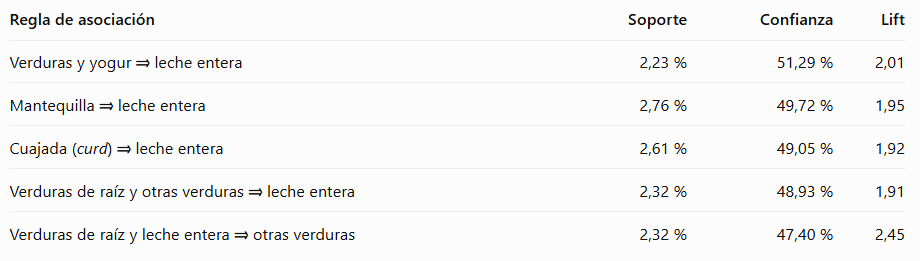




Interpretación en lenguaje de negocio:
1. Verduras y yogur ⇒ leche entera: los clientes que compran verduras y yogur también suelen incluir leche entera, por lo que el supermercado podría recomendarla junto a esos productos.
2. Mantequilla ⇒ leche entera: casi la mitad de las compras con mantequilla también incluyen leche entera, por lo que sería conveniente exhibir ambos productos en una zona accesible.
3. Cuajada ⇒ leche entera: los clientes que compran cuajada muestran una tendencia a comprar también leche entera, lo que permitiría probar una promoción conjunta.
4. Verduras de raíz y otras verduras ⇒ leche entera: quienes compran ambos tipos de verduras también pueden estar interesados en llevar leche, por lo que se podría recomendar este producto al momento de pagar.
5. Verduras de raíz y leche entera ⇒ otras verduras: la compra conjunta de verduras de raíz y leche entera se relaciona con una mayor presencia de otras verduras, lo que podría ayudar a organizar la sección de productos frescos.

# 2. Una regla que descartaría
Descartaría como prioridad comercial la regla panecillos (rolls/buns) ⇒ leche entera, si aparece en los resultados de mi notebook con estos valores de referencia:
- Soporte: 18,44 %
- Confianza: 31,54 %
- Lift: 1,25.

Aunque es una combinación relativamente frecuente, su confianza es baja y su lift indica que la relación es solamente moderada

# 3. Decisión concreta para el administrador
El administrador podría probar una promoción que reúna mantequilla y leche entera, ubicando ambos productos en sectores cercanos o mostrando una recomendación de leche cuando el cliente compre mantequilla. Después, compararía las ventas antes y después de la promoción para comprobar si realmente aumenta la compra conjunta.